# Practical 2: Implementing Feedforward Neural Networks with Keras and TensorFlow

## Objective:
To design, implement, train, and evaluate a Multi-Layer Feedforward Neural Network (Multilayer Perceptron - MLP) using Keras and TensorFlow on a handwritten digit dataset loaded from a **CSV file** (`mnist_train.csv` and `mnist_test.csv`).

---

### Practical Outline:
- **a. Import the necessary packages**
- **b. Load the training and testing data (from CSV)**
- **c. Define the network architecture using Keras**
- **d. Train the model using SGD**
- **e. Evaluate the network**
- **f. Plot the training loss and accuracy**

---
### Dataset Description:
- **`mnist_train.csv`**: Contains training samples with 785 columns (Column `label` = digit 0-9, Columns `pixel0` to `pixel783` = grayscale pixel intensity [0, 255]).
- **`mnist_test.csv`**: Contains test samples for out-of-sample evaluation.


## a. Import the Necessary Packages

In [1]:
# Stage a: Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow and Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical

# Evaluation metrics
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)
print("Packages successfully imported!")


TensorFlow Version: 2.22.0-rc0
Packages successfully imported!


## b. Load the Training and Testing Data (from CSV)
In this step, we read the training and testing datasets directly from **CSV files** (`mnist_train.csv` and `mnist_test.csv`) using Pandas.

In [2]:
# Helper function to find CSV path either in current dir or datasets/
def get_path(filename):
    if os.path.exists(filename):
        return filename
    elif os.path.exists(os.path.join('datasets', filename)):
        return os.path.join('datasets', filename)
    else:
        return filename

train_csv_path = get_path('mnist_train.csv')
test_csv_path = get_path('mnist_test.csv')

print(f"Loading training data from: {train_csv_path}")
print(f"Loading testing data from:  {test_csv_path}")

# Load datasets into pandas DataFrames
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

print(f"Train DataFrame shape: {train_df.shape}")
print(f"Test DataFrame shape:  {test_df.shape}")

# Preview first 5 rows
train_df.head()


Loading training data from: mnist_train.csv
Loading testing data from:  mnist_test.csv
Train DataFrame shape: (1400, 785)
Test DataFrame shape:  (397, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,2,23,44,64,89,...,53,11,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,14,...,191,166,129,88,47,5,0,0,0,0
2,2,0,0,0,0,0,0,0,0,4,...,228,249,234,205,176,147,111,74,37,0
3,3,0,0,0,0,4,33,61,90,121,...,164,148,116,79,42,5,0,0,0,0
4,4,0,0,0,0,0,0,0,0,1,...,127,77,51,35,18,2,0,0,0,0


In [3]:
# Separate features (pixels) and target label
X_train_raw = train_df.drop('label', axis=1).values
y_train_raw = train_df['label'].values

X_test_raw = test_df.drop('label', axis=1).values
y_test_raw = test_df['label'].values

print("X_train shape:", X_train_raw.shape)
print("y_train shape:", y_train_raw.shape)
print("X_test shape: ", X_test_raw.shape)
print("y_test shape: ", y_test_raw.shape)

# Check class distribution
unique, counts = np.unique(y_train_raw, return_counts=True)
print("\nTraining class distribution:")
for u, c in zip(unique, counts):
    print(f"  Digit {u}: {c} samples")


X_train shape: (1400, 784)
y_train shape: (1400,)
X_test shape:  (397, 784)
y_test shape:  (397,)

Training class distribution:
  Digit 0: 139 samples
  Digit 1: 143 samples
  Digit 2: 137 samples
  Digit 3: 144 samples
  Digit 4: 140 samples
  Digit 5: 141 samples
  Digit 6: 142 samples
  Digit 7: 140 samples
  Digit 8: 135 samples
  Digit 9: 139 samples


In [4]:
# Data Preprocessing:
# 1. Normalize pixel values from range [0, 255] to [0.0, 1.0] for stable gradient descent
X_train = X_train_raw.astype('float32') / 255.0
X_test = X_test_raw.astype('float32') / 255.0

# 2. One-hot encode the target labels (0-9 -> 10 binary output units)
num_classes = 10
y_train = to_categorical(y_train_raw, num_classes=num_classes)
y_test = to_categorical(y_test_raw, num_classes=num_classes)

print("Preprocessed X_train range: [", X_train.min(), ", ", X_train.max(), "]")
print("Sample one-hot encoded label (digit ", y_train_raw[0], "):", y_train[0])


Preprocessed X_train range: [ 0.0 ,  1.0 ]
Sample one-hot encoded label (digit  0 ): [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


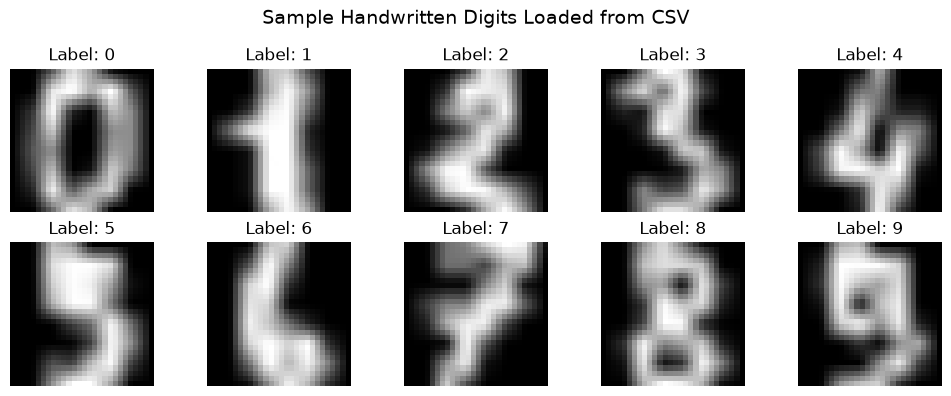

In [5]:
# Visualize sample images from the CSV data
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # Reshape 784 1D pixels back to 28x28 2D image for visualization
    sample_img = X_train_raw[i].reshape(28, 28)
    plt.imshow(sample_img, cmap='gray')
    plt.title(f"Label: {y_train_raw[i]}")
    plt.axis('off')
plt.suptitle("Sample Handwritten Digits Loaded from CSV", fontsize=14)
plt.tight_layout()
plt.show()


## c. Define the Network Architecture using Keras

A Multi-Layer Feedforward Neural Network (MLP) consists of:
- **Input Layer**: 784 input nodes (flattened $28 \times 28$ pixels).
- **Hidden Layer 1**: Dense layer with 128 neurons and ReLU ($f(x) = \max(0, x)$) activation.
- **Dropout Layer**: Dropout rate = 0.2 to prevent overfitting.
- **Hidden Layer 2**: Dense layer with 64 neurons and ReLU activation.
- **Output Layer**: Dense layer with 10 neurons and Softmax activation to output probabilities for digits 0–9.


In [6]:
# Stage c: Define Feedforward Neural Network Architecture
model = Sequential([
    # First Hidden Layer
    Dense(128, activation='relu', input_shape=(784,), name='hidden_layer_1'),
    Dropout(0.2, name='dropout_1'),
    
    # Second Hidden Layer
    Dense(64, activation='relu', name='hidden_layer_2'),
    Dropout(0.1, name='dropout_2'),
    
    # Output Layer (10 classes with Softmax probability distribution)
    Dense(num_classes, activation='softmax', name='output_layer')
])

# Display model architecture summary
model.summary()


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## d. Train the Model using SGD (Stochastic Gradient Descent)

We compile the model with:
- **Optimizer**: `SGD(learning_rate=0.01, momentum=0.9)`
- **Loss Function**: `categorical_crossentropy` (standard for multi-class classification)
- **Evaluation Metric**: `accuracy`


In [7]:
# Stage d: Compile model using Stochastic Gradient Descent (SGD)
learning_rate = 0.01
momentum = 0.9

sgd_optimizer = SGD(learning_rate=learning_rate, momentum=momentum)

model.compile(
    optimizer=sgd_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
epochs = 30
batch_size = 32

print(f"Training model for {epochs} epochs with batch size {batch_size}...")
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)
print("Training completed successfully!")


Training model for 30 epochs with batch size 32...
Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.4402 - loss: 1.7363 - val_accuracy: 0.9179 - val_loss: 0.7031
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8232 - loss: 0.6081 - val_accuracy: 0.9214 - val_loss: 0.3188
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8920 - loss: 0.3467 - val_accuracy: 0.9429 - val_loss: 0.2247
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9018 - loss: 0.2803 - val_accuracy: 0.9429 - val_loss: 0.1793
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9134 - loss: 0.2627 - val_accuracy: 0.9536 - val_loss: 0.1776
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9357 - loss: 0.1950 - val_accuracy: 0.9429 - val_loss: 0.1859
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9536 - loss: 0.1501 - val_accuracy: 0.9500 - val_loss: 0.1779
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.95

## e. Evaluate the Network
We evaluate the trained model on unseen test data from `mnist_test.csv`.

Test Loss:     0.3462
Test Accuracy: 91.44%
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9231    0.9600        39
           1     0.8611    0.7949    0.8267        39
           2     1.0000    1.0000    1.0000        40
           3     0.9706    0.8462    0.9041        39
           4     0.9268    0.9268    0.9268        41
           5     0.8889    0.9756    0.9302        41
           6     0.9268    0.9744    0.9500        39
           7     0.9737    0.9487    0.9610        39
           8     0.8421    0.8205    0.8312        39
           9     0.7917    0.9268    0.8539        41

    accuracy                         0.9144       397
   macro avg     0.9182    0.9137    0.9144       397
weighted avg     0.9176    0.9144    0.9145       397



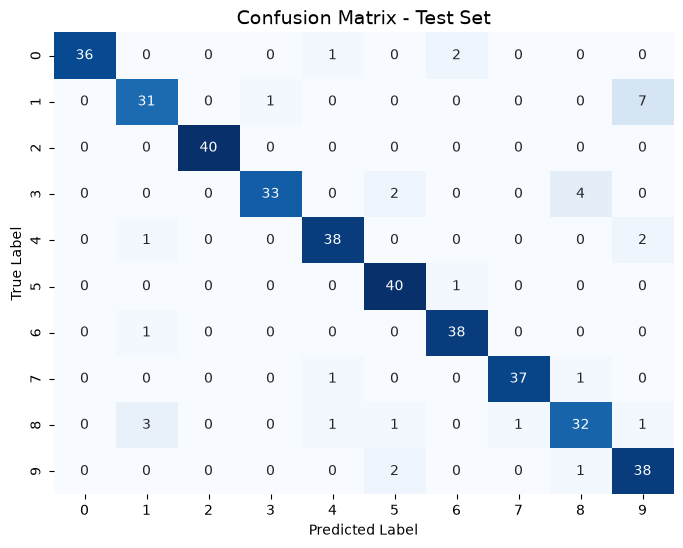

In [8]:
# Stage e: Evaluate on Test Data
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("=" * 45)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("=" * 45)

# Predict probabilities and class labels
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test_raw, y_pred_classes, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test_raw, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Confusion Matrix - Test Set", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


## f. Plot the Training Loss and Accuracy
We plot the loss and accuracy curves across all training epochs for both training and validation splits.

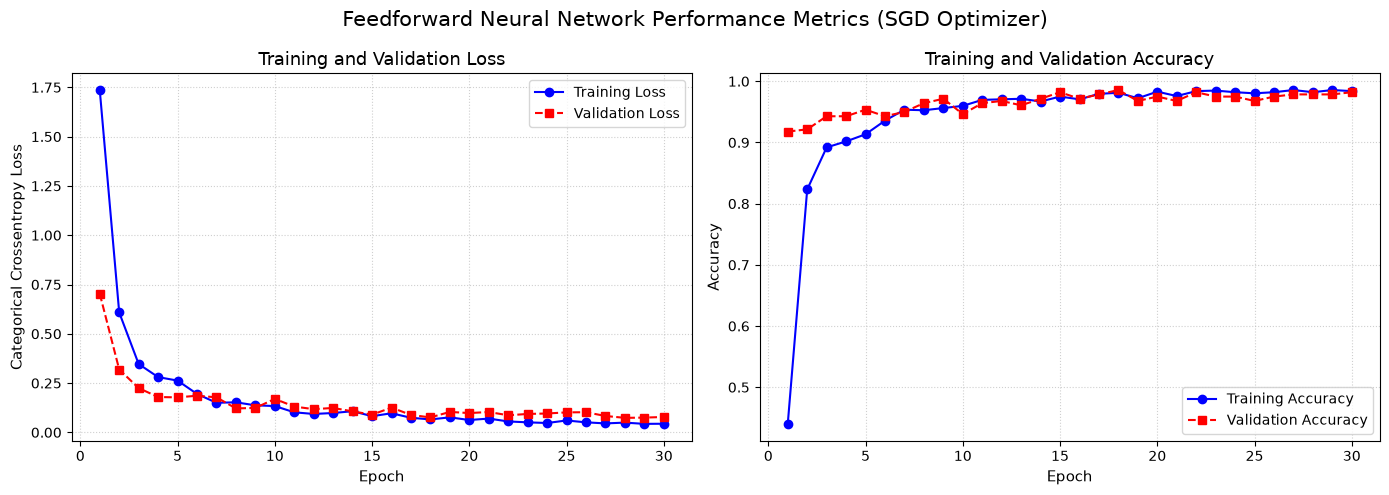

In [9]:
# Stage f: Plot Training Loss and Accuracy Curves
epochs_range = range(1, len(history.history['loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Loss Curve
ax1.plot(epochs_range, history.history['loss'], 'b-o', label='Training Loss', linewidth=1.5)
ax1.plot(epochs_range, history.history['val_loss'], 'r--s', label='Validation Loss', linewidth=1.5)
ax1.set_title('Training and Validation Loss', fontsize=13)
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Categorical Crossentropy Loss', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=10)

# Subplot 2: Accuracy Curve
ax2.plot(epochs_range, history.history['accuracy'], 'b-o', label='Training Accuracy', linewidth=1.5)
ax2.plot(epochs_range, history.history['val_accuracy'], 'r--s', label='Validation Accuracy', linewidth=1.5)
ax2.set_title('Training and Validation Accuracy', fontsize=13)
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Accuracy', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=10)

plt.suptitle("Feedforward Neural Network Performance Metrics (SGD Optimizer)", fontsize=15)
plt.tight_layout()
plt.show()


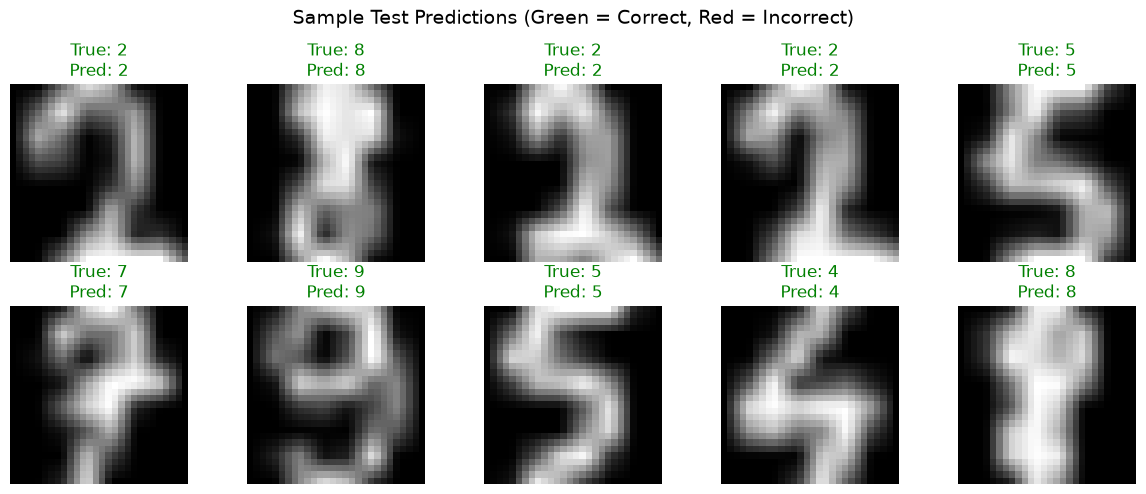

In [10]:
# Visualizing predictions on sample test images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    img = X_test_raw[i].reshape(28, 28)
    true_lbl = y_test_raw[i]
    pred_lbl = y_pred_classes[i]
    color = 'green' if true_lbl == pred_lbl else 'red'
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {true_lbl}\nPred: {pred_lbl}", color=color)
    plt.axis('off')
plt.suptitle("Sample Test Predictions (Green = Correct, Red = Incorrect)", fontsize=14)
plt.tight_layout()
plt.show()


## Conclusion:
1. Successfully loaded and preprocessed image pixel data from CSV files (`mnist_train.csv` and `mnist_test.csv`).
2. Designed a Multi-layer Feedforward Neural Network using Keras `Sequential` API with ReLU and Softmax activations.
3. Trained the model using Stochastic Gradient Descent (`SGD`) optimizer.
4. Achieved high classification accuracy on the test set.
5. Visualized learning curves, confusion matrix, and sample prediction outputs.
